# This is my project code for Thailand road flooding

In [21]:
# Import files
from pathlib import Path

import geopandas
import pandas
import rasterio
from matplotlib import pyplot
from rasterio.plot import show
from rasterio.plot import show_hist
import re

from pyproj import Geod

## Give the folder paths

In [22]:
# set up variables for incoming and processed data paths
project_path = Path().resolve().parent # assume we're running from the project scripts directory, so get the parent
incoming_data_path = project_path / "incoming_data/starter-data-kit/data/THA"
processed_data_path = project_path / "processed_data"

## Read the input files

In [23]:
# Read the flood raster file
hazard = rasterio.open(incoming_data_path / "jrc_floods/floodMapGL_rp100y__THA.tif")
# Read admin boundary
tha_admin = geopandas.read_file(incoming_data_path /"geoboundaries/geoBoundaries-THA-ADM1.gpkg")
# Read the roads file
roads = geopandas.read_file(incoming_data_path /"openstreetmap/openstreetmap_roads-tertiary__THA.gpkg",layer="lines")

## Plot the raster file on a map and create the histogram of flood depths

/Users/raghavpant/micromamba/envs/snail-datapkg/lib/python3.12/site-packages/matplotlib/colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


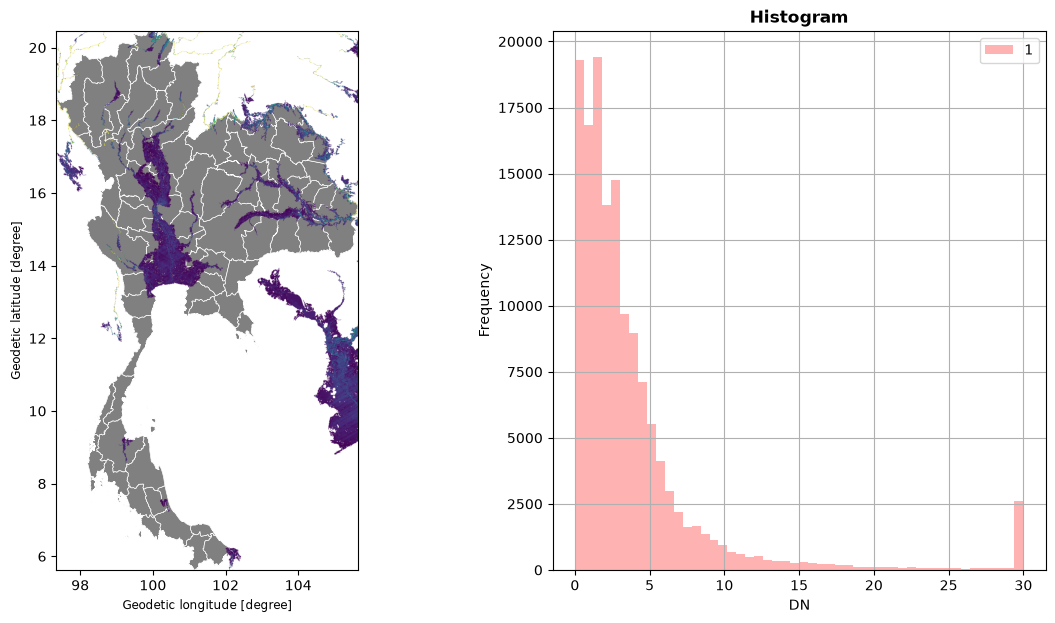

In [26]:
fig, (axrgb, axhist) = pyplot.subplots(1, 2, figsize=(14,7))
tha_admin.plot(ax=axrgb,zorder=0,edgecolor='w',color='grey',linewidth=0.5)
show(hazard, ax=axrgb)
show_hist(hazard, bins=50, histtype='stepfilled',alpha=0.3, ax=axhist)
pyplot.savefig(processed_data_path /"thailand_flood.png")

## Plot the roads for Thailand and save the file

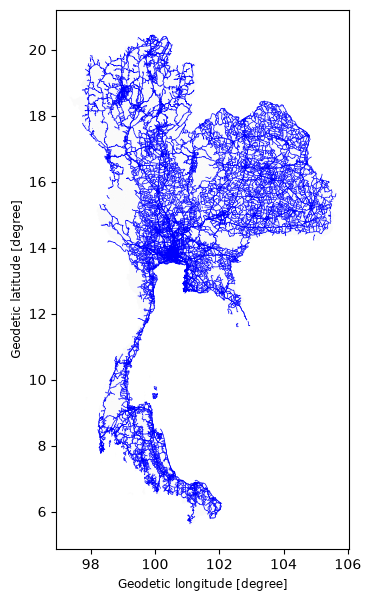

In [27]:
fig, ax = pyplot.subplots(1, 1, figsize=(14,7))
tha_admin.plot(ax=ax,zorder=0,edgecolor='w',color='#f0f0f0',alpha=0.3,linewidth=0.5)
roads.plot(ax=ax,zorder=1,edgecolor='b',linewidth=0.5)
pyplot.savefig(processed_data_path /"tha_roads.png")

In [47]:
def get_values(string):
    st_list = string.split("_")
    rcp = st_list[0]
    model = st_list[1]
    year = int(st_list[2])
    rp = int(st_list[3].replace("rp",""))

    return rcp, model, year, rp
        
hazard_paths = list((incoming_data_path / "aqueduct_flood").glob("*.tif"))
hazard_files = pandas.DataFrame({"path": hazard_paths})
hazard_files["key"] = [Path(path).stem for path in hazard_paths]
hazard_files["key"] = hazard_files["key"].str.replace("__THA","")
hazard_files["values"] = hazard_files.apply(lambda x: get_values(x["key"]),axis=1)
hazard_files[["rcp","model","year","rp"]] = hazard_files["values"].apply(pandas.Series)
hazard_files.drop("values",axis=1,inplace=True)
hazard_files

,path,key,rcp,model,year,rp
0,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp4p5_00IPSL-CM5A-LR_2030_rp00250,rcp4p5,00IPSL-CM5A-LR,2030,250
1,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp8p5_MIROC-ESM-CHEM_2080_rp00250,rcp8p5,MIROC-ESM-CHEM,2080,250
2,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inuncoast_historical_wtsub_hist_rp0010_0,historical,wtsub,hist,10
3,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp4p5_0000GFDL-ESM2M_2050_rp00025,rcp4p5,0000GFDL-ESM2M,2050,25
4,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp8p5_00000NorESM1-M_2030_rp00250,rcp8p5,00000NorESM1-M,2030,250
...,...,...,...,...,...,...
364,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp4p5_0000HadGEM2-ES_2080_rp00100,rcp4p5,0000HadGEM2-ES,2080,100
365,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inuncoast_rcp4p5_wtsub_2080_rp0010_0,rcp4p5,wtsub,2080,10
366,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inunriver_rcp8p5_00000NorESM1-M_2080_rp00050,rcp8p5,00000NorESM1-M,2080,50
367,/Users/raghavpant/Desktop/EMP-APAC/snail-datap...,inuncoast_rcp4p5_wtsub_2050_rp0010_0,rcp4p5,wtsub,2050,10
